<u>**Q1. Create a file “people.txt” with the following data:**</u>

"AGE",&emsp;    "AGEGROUP",  &emsp;   "HEIGHT", &emsp;     "STATUS", &emsp;     "YEARSMARRIED" <br>
&emsp;21,&emsp;&emsp;&emsp;&emsp;"adult",&emsp;&emsp;&emsp;&emsp;6.0,&emsp;&emsp;&emsp;&emsp;"single",&emsp;&emsp;&emsp;&emsp;-1 <br>
&nbsp;&emsp;2, &emsp;&emsp;&emsp;&emsp;"child",&emsp;&emsp;&emsp;&emsp;&nbsp;&nbsp;3,&emsp;&emsp;&emsp;&emsp;"married",&emsp;&emsp;&emsp;&emsp;0 <br>
&nbsp;&emsp;18,&emsp;&emsp;&emsp;&emsp;"adult",&emsp;&emsp;&emsp;&emsp;5.7,&emsp;&emsp;&emsp;&emsp;"married",&emsp;&emsp;&emsp;&emsp;20 <br>
&nbsp;&emsp;221,&emsp;&emsp;&emsp;&emsp;"elderly",&emsp;&emsp;&emsp;&emsp;5,&emsp;&emsp;&emsp;&emsp;"widowed",&emsp;&emsp;&emsp;&emsp;2 <br>
&nbsp;&emsp;34,&emsp;&emsp;&emsp;&emsp;"child",&emsp;&emsp;&emsp;&emsp;-7,&emsp;&emsp;&emsp;&emsp;"married",&emsp;&emsp;&emsp;&emsp;3

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

<u>**(i)Read the data from the file “people.txt”.**</u>

In [86]:
df = pd.read_table("people.txt", delimiter=",")

In [87]:
df

,AGE,AGEGROUP,HEIGHT,STATUS,YEARSMARRIED
0,21,adult,6.0,single,-1
1,2,child,3.0,married,0
2,18,adult,5.7,married,20
3,221,elderly,5.0,widowed,2
4,34,child,-7.0,married,3


In [88]:
df.describe()

,AGE,HEIGHT,YEARSMARRIED
count,5.000000,5.00000,5.000000
mean,59.200000,2.54000,4.800000
std,91.163041,5.45967,8.642916
min,2.000000,-7.00000,-1.000000
25%,18.000000,3.00000,0.000000
50%,21.000000,5.00000,2.000000
75%,34.000000,5.70000,3.000000
max,221.000000,6.00000,20.000000


In [89]:
print(df.describe())

              AGE   HEIGHT  YEARSMARRIED
count    5.000000  5.00000      5.000000
mean    59.200000  2.54000      4.800000
std     91.163041  5.45967      8.642916
min      2.000000 -7.00000     -1.000000
25%     18.000000  3.00000      0.000000
50%     21.000000  5.00000      2.000000
75%     34.000000  5.70000      3.000000
max    221.000000  6.00000     20.000000


**<u>(ii)Create a ruleset E that contain rules to check for the following conditions:</u>**
1. The age should be in the range 0-150. 
2. The age should be greater than years married. 
3. The status should be married or single or widowed. 
4. If age is less than 18 the age group should be child, if age is between 18 and 65 the age group should be adult, if age is more than 65 the age group should be elderly.


In [90]:
def ruleset(df):
    df['Rule1']= df['AGE'].apply(lambda x:True if x>0 and x<150 else False)
    df['Rule2']= df.apply(lambda x:True if x.AGE > x.YEARSMARRIED else False, axis=1)
    df['Rule3']= df['STATUS'].apply(lambda x:True if x == 'married' or x== 'single' or x=='widowed' else False)
    df['Rule4']= df.apply(lambda x:True if ((x.AGE < 18 and x.AGEGROUP == 'child') or
                                        (x.AGE >= 18 and x.AGE <= 65 and x.AGEGROUP == 'adult') or
                                        (x.AGE > 65 and x.AGEGROUP == 'elderly'))
                                         else False, axis=1)

In [91]:
ruleset(df)

In [92]:
df

,AGE,AGEGROUP,HEIGHT,STATUS,YEARSMARRIED,Rule1,Rule2,Rule3,Rule4
0,21,adult,6.0,single,-1,True,True,True,True
1,2,child,3.0,married,0,True,True,True,True
2,18,adult,5.7,married,20,True,False,True,True
3,221,elderly,5.0,widowed,2,False,True,True,True
4,34,child,-7.0,married,3,True,True,True,False


**<u>iii) Check whether ruleset E is violated by the data in the file people.txt.</u>**

In [93]:
ruleset(df)
df

,AGE,AGEGROUP,HEIGHT,STATUS,YEARSMARRIED,Rule1,Rule2,Rule3,Rule4
0,21,adult,6.0,single,-1,True,True,True,True
1,2,child,3.0,married,0,True,True,True,True
2,18,adult,5.7,married,20,True,False,True,True
3,221,elderly,5.0,widowed,2,False,True,True,True
4,34,child,-7.0,married,3,True,True,True,False


**<u>iv) Summarize the results obtained in part (iii).</u>**

In [94]:
df_rule_followed = df.iloc[:,5:]
df_rule_followed

,Rule1,Rule2,Rule3,Rule4
0,True,True,True,True
1,True,True,True,True
2,True,False,True,True
3,False,True,True,True
4,True,True,True,False


In [95]:
df_rule_followed = df_rule_followed.astype(int)
df_rule_followed

,Rule1,Rule2,Rule3,Rule4
0,1,1,1,1
1,1,1,1,1
2,1,0,1,1
3,0,1,1,1
4,1,1,1,0


In [96]:
df_rule_followed.describe()

,Rule1,Rule2,Rule3,Rule4
count,5.000000,5.000000,5.0,5.000000
mean,0.800000,0.800000,1.0,0.800000
std,0.447214,0.447214,0.0,0.447214
min,0.000000,0.000000,1.0,0.000000
25%,1.000000,1.000000,1.0,1.000000
50%,1.000000,1.000000,1.0,1.000000
75%,1.000000,1.000000,1.0,1.000000
max,1.000000,1.000000,1.0,1.000000


**v) Visualize the results obtained in part (iii)**

Text(0, 0.5, 'no. of rules violated')

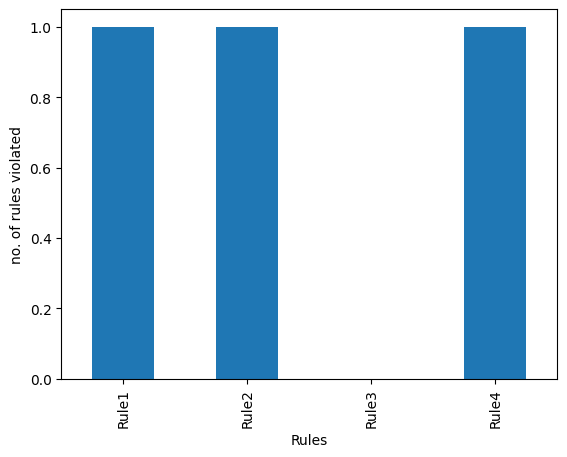

In [97]:
plt.figure
df_rule_followed.apply(lambda x: len(x) -  x.sum()).plot(kind='bar')
plt.xlabel('Rules')
plt.ylabel('no. of rules violated')